[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/multigeom/multigeom-tutorials/blob/main/notebooks/f3_fisher_information.ipynb)

# Fisher information

* **Author**: simone.azeglio@gmail.com

* **Goal**: How well can two nearby stimuli be told apart from the responses of a neuron?

* **Needs**: a CPU, no data.

* **Time**: about 5 s.

* **Track**: Foundations, notebook 3. The Fisher information $J(x)$ is the starting point of Section 2 of Azeglio, Laquitaine, Ferrari, Chalk (NeurIPS 2026, arXiv 2605.06304).

* **Next**: notebook f4 turns the Fisher information into a distance between stimuli.

## 1. Setup

### 1.1. Install package

On Google Colab, install `multigeom`. Elsewhere this cell does nothing.

time: <1 sec

In [1]:
%%time

# on Google Colab install the package from PyPI, without its dependencies: Colab already
# has torch, numpy, scipy and matplotlib, and reinstalling torch is slow and can break
# the GPU runtime (nothing to do on your own machine)
import sys

if "google.colab" in sys.modules:
    %pip install -q --no-deps --pre multigeom

CPU times: user 4 μs, sys: 1 μs, total: 5 μs
Wall time: 6.91 μs


### 1.2. Imports

Import the packages, pick the device, compute in float64 and set the figure style. The device is `cuda` when there is a GPU and `cpu` otherwise, never `mps`, which has no float64.

time: <1 sec

In [2]:
%%time

import math

import matplotlib.pyplot as plt
import torch

from multigeom.lowdim import compute_fisher, response_density

# run on the GPU when there is one
device = "cuda" if torch.cuda.is_available() else "cpu"
torch.set_default_dtype(torch.float64)
print("device:", device)

# figure style of the Foundations notebooks: 9 pt text or more, no top or right spines
plt.rcParams.update(
    {
        "font.size": 10,
        "axes.labelsize": 10,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "legend.fontsize": 9,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "legend.frameon": False,
    }
)
TEAL, ROSE, VIOLET, INK, GREY = "#2A8C7E", "#B23A62", "#5b3fd1", "#1a1a1a", "#8a8a8a"

device: cpu
CPU times: user 716 ms, sys: 92.9 ms, total: 809 ms
Wall time: 817 ms


### 1.3. Parameters of the series

The stimulus $x$ lies on $[-3, 3]$, sampled on 1,201 grid points. The neuron has the bell-shaped tuning curve $f(x) = e^{-x^2/2}$, and its response is $r = f(x) + \sigma z$, with $z$ a standard Gaussian and $\sigma = 0.1$. Its response distribution is

$$p(r \mid x) = \mathcal{N}\big(r;\, f(x),\, \sigma^2\big).$$

The cell also defines $\Phi$, the cumulative distribution function of the standard Gaussian.

time: <1 sec

In [3]:
%%time

X_MIN, X_MAX = -3.0, 3.0  # stimulus range
N_X = 1201  # stimulus grid points (step 0.005)
SIGMA = 0.1  # standard deviation of the response noise

x = torch.linspace(X_MIN, X_MAX, N_X, device=device)


def bell(x):
    """Tuning curve of the bell-shaped neuron, f(x) = exp(-x^2 / 2)."""
    return torch.exp(-(torch.as_tensor(x) ** 2) / 2)


def Phi(z):
    """Cumulative distribution function of the standard Gaussian."""
    return torch.special.ndtr(torch.as_tensor(z)).item()


f = bell(x)

CPU times: user 247 μs, sys: 177 μs, total: 424 μs
Wall time: 345 μs


## 2. Two nearby stimuli

Take two stimuli a step $\delta$ apart, $x$ and $x + \delta$. Their response distributions are two Gaussians of width $\sigma$, and the discriminability $d'$ is the distance between their means in units of the noise:

$$d' = \frac{\lvert f(x+\delta) - f(x) \rvert}{\sigma}.$$

An observer sees one response, knows both response distributions, and must say which stimulus was shown, each with probability one half. The best rule picks the stimulus whose mean is closer to the response. This ideal observer is correct with probability $\Phi(d'/2)$.

The next cell compares two pairs a step $\delta = 0.4$ apart, one on the flank of the tuning curve and one at its peak.

time: <1 sec

In [4]:
%%time

DELTA = 0.4
PAIRS = {"flank": (-1.35, -0.95), "peak": (0.0, 0.4)}


def discriminability(a, b, sigma=SIGMA):
    """d' of the stimuli a and b for the bell-shaped neuron."""
    return abs(bell(b).item() - bell(a).item()) / sigma


d_prime = {name: discriminability(a, b) for name, (a, b) in PAIRS.items()}
for name, (a, b) in PAIRS.items():
    print(
        f"{name:5s} pair {a:+.2f}, {b:+.2f}: mean {bell(a).item():.2f} -> "
        f"{bell(b).item():.2f}, d' = {d_prime[name]:.2f}, "
        f"correct {100 * Phi(d_prime[name] / 2):.0f}%"
    )
print("expected: flank d' = 2.35, 88% | peak d' = 0.77, 65%")

flank pair -1.35, -0.95: mean 0.40 -> 0.64, d' = 2.35, correct 88%
peak  pair +0.00, +0.40: mean 1.00 -> 0.92, d' = 0.77, correct 65%
expected: flank d' = 2.35, 88% | peak d' = 0.77, 65%
CPU times: user 384 μs, sys: 107 μs, total: 491 μs
Wall time: 527 μs


The two pairs are equally far apart in the stimulus. The peak pair, where the neuron responds most, is the harder one to tell apart.

## 3. Fisher information

For a small step, the mean response changes by the slope times the step, $f(x+\delta) \approx f(x) + f'(x)\,\delta$, so $d' \approx \lvert f'(x) \rvert\, \delta / \sigma$. The square of the factor in front of $\delta$ is the Fisher information:

$$J(x) = \frac{f'(x)^2}{\sigma^2}, \qquad d' \approx \sqrt{J(x)}\;\delta .$$

`compute_fisher(x, f, sigma)` returns $J$ on the grid, with the slope taken by central differences. For our neuron $J(x) = x^2 e^{-x^2}/\sigma^2$, which is zero at the peak and largest at $x = \pm 1$. The figure shows the tuning curve with a band of $\pm\sigma$ and the two pairs, and $J$ in teal.

time: <1 sec

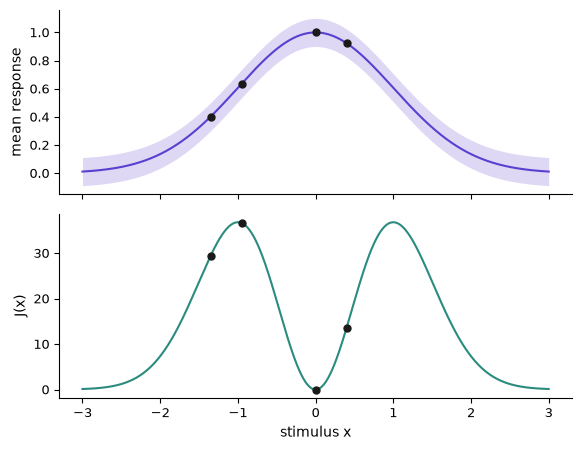

CPU times: user 70.3 ms, sys: 3.78 ms, total: 74.1 ms
Wall time: 76.9 ms


In [5]:
%%time

J = compute_fisher(x, f, SIGMA)

fig, (ax, ax_j) = plt.subplots(2, 1, figsize=(6, 4.6), sharex=True)
ax.fill_between(
    x.cpu(), (f - SIGMA).cpu(), (f + SIGMA).cpu(), color=VIOLET, alpha=0.2, lw=0
)
ax.plot(x.cpu(), f.cpu(), color=VIOLET)
ax_j.plot(x.cpu(), J.cpu(), color=TEAL)
for pair in PAIRS.values():
    stimuli = torch.tensor(pair)
    ax.plot(stimuli, bell(stimuli), "o", color=INK, ms=5)
    ax_j.plot(
        stimuli, stimuli**2 * torch.exp(-(stimuli**2)) / SIGMA**2, "o", color=INK, ms=5
    )
ax.set_ylabel("mean response")
ax_j.set_ylabel("J(x)")
ax_j.set_xlabel("stimulus x")
plt.tight_layout()
plt.show()

The next cell reads three numbers from $J$. Its largest value, the $d'$ that it predicts for a step of 0.1 there, and its prediction for the two pairs, against the exact $d'$ of Section 2.

time: <1 sec

In [6]:
%%time


def fisher_at(value):
    """J on the grid point nearest to the stimulus `value`."""
    return J[torch.argmin((x - value).abs())].item()


J_max = J.max().item()
x_at_max = x[torch.argmax(J)].abs().item()
predicted = {name: math.sqrt(fisher_at(a)) * DELTA for name, (a, _) in PAIRS.items()}

print(f"largest J = {J_max:.1f} at |x| = {x_at_max:.2f}   (expected 36.8 at 1)")
print(
    f"predicted d' of a step of 0.1 there: {math.sqrt(J_max) * 0.1:.2f}"
    "   (expected 0.61)"
)
print(f"J(-1.35) = {fisher_at(-1.35):.1f}   (expected 29.5)")
for name in PAIRS:
    print(
        f"{name:5s} pair: sqrt(J) delta = {predicted[name]:.2f}, "
        f"exact d' = {d_prime[name]:.2f}"
    )
print("expected: flank 2.17 against 2.35 | peak 0 against 0.77")

largest J = 36.8 at |x| = 1.00   (expected 36.8 at 1)
predicted d' of a step of 0.1 there: 0.61   (expected 0.61)
J(-1.35) = 29.5   (expected 29.5)
flank pair: sqrt(J) delta = 2.17, exact d' = 2.35
peak  pair: sqrt(J) delta = 0.00, exact d' = 0.77
expected: flank 2.17 against 2.35 | peak 0 against 0.77
CPU times: user 320 μs, sys: 117 μs, total: 437 μs
Wall time: 402 μs


On the flank the prediction is close to the exact value. At the peak $J = 0$ predicts $d' = 0$, while the pair can still be told apart, because the tuning curve bends there. The Fisher information describes only steps small enough for the tuning curve to look straight.

## 4. The score

For any response distribution, the score of one response is

$$s(r, x) = \frac{\partial}{\partial x} \ln p(r \mid x).$$

It says how strongly that response favours a slightly larger stimulus over $x$. When $x$ is the stimulus shown, the score averages to zero over responses, and the Fisher information is its variance:

$$J(x) = \mathbb{E}_{r \mid x}\big[s(r, x)^2\big].$$

The next cell draws 100,000 responses to $x = -1$ with a fixed random generator. It computes the score of each response by automatic differentiation of $\ln p(r \mid x)$, with one copy of the stimulus per response. It checks the result against the exact score of the Gaussian, $s(r, x) = (r - f(x))\, f'(x)/\sigma^2$, and compares the mean and the variance of the scores with 0 and $J(-1)$.

time: <1 sec

In [7]:
%%time

X_PROBE = -1.0
N_REPEATS = 100_000

generator = torch.Generator(device=device).manual_seed(0)
noise = torch.randn(N_REPEATS, generator=generator, device=device)
responses = bell(X_PROBE).item() + SIGMA * noise

x_copies = torch.full_like(responses, X_PROBE, requires_grad=True)
log_likelihood = torch.distributions.Normal(bell(x_copies), SIGMA).log_prob(responses)
(scores,) = torch.autograd.grad(log_likelihood.sum(), x_copies)

slope_probe = -X_PROBE * bell(X_PROBE).item()  # f'(x) = -x exp(-x^2 / 2)
scores_exact = (responses - bell(X_PROBE).item()) * slope_probe / SIGMA**2
J_probe = slope_probe**2 / SIGMA**2
score_mean, score_variance = scores.mean().item(), scores.var().item()
standard_error = J_probe * math.sqrt(2 / N_REPEATS)  # of the sample variance

print(f"largest |autograd - exact|: {(scores - scores_exact).abs().max().item():.1e}")
print(f"mean of the score:     {score_mean:+.3f}   (expected 0)")
print(f"variance of the score: {score_variance:.2f}   (J(-1) = {J_probe:.2f})")
print(f"difference: {(score_variance - J_probe) / standard_error:+.1f} standard errors")

largest |autograd - exact|: 7.1e-15
mean of the score:     -0.003   (expected 0)
variance of the score: 37.11   (J(-1) = 36.79)
difference: +1.9 standard errors
CPU times: user 7.2 ms, sys: 5.82 ms, total: 13 ms
Wall time: 21.8 ms


Automatic differentiation gives the exact score. The variance of the scores is close to $J(-1)$, and the difference is about twice the standard error of a sample variance from 100,000 repeats, which is 0.45% of $J$.

The Fisher information also measures how far apart two nearby response distributions are. The Kullback-Leibler divergence in nats, $D_{\mathrm{KL}}(p \,\Vert\, q) = \mathbb{E}_{r \sim p}[\ln p(r) - \ln q(r)]$, satisfies

$$D_{\mathrm{KL}}\big(p(r \mid x) \,\Vert\, p(r \mid x+\delta)\big) \approx \tfrac{1}{2}\, J(x)\, \delta^2 .$$

The next cell computes the divergence of the flank pair by quadrature on a response grid and compares it with this approximation.

time: <1 sec

In [8]:
%%time

a, b = PAIRS["flank"]
r_axis = torch.linspace(-0.5, 1.5, 4001, device=device)
p = response_density(bell(a)[None], SIGMA, r_axis)[0]
q = response_density(bell(b)[None], SIGMA, r_axis)[0]
kl_flank = (p * (p / q).log()).sum().item() * (r_axis[1] - r_axis[0]).item()

print(f"KL of the flank pair: {kl_flank:.2f} nats   (expected 2.76 = d'^2 / 2)")
print(f"J(-1.35) delta^2 / 2: {fisher_at(a) * DELTA**2 / 2:.2f} nats   (expected 2.36)")

KL of the flank pair: 2.76 nats   (expected 2.76 = d'^2 / 2)
J(-1.35) delta^2 / 2: 2.36 nats   (expected 2.36)
CPU times: user 444 μs, sys: 113 μs, total: 557 μs
Wall time: 525 μs


## 5. The Cramér-Rao bound

An estimator is a rule $\hat{x}(r)$ that turns a response into a guess of the stimulus. An unbiased estimator has an average guess equal to the true stimulus. The Cramér-Rao bound states that every unbiased estimator has

$$\mathrm{Var}\big[\hat{x}(r)\big] \;\ge\; \frac{1}{J(x)} ,$$

so its standard deviation is at least $1/\sqrt{J(x)}$. We check the bound by simulation with the estimator that inverts the left half of the tuning curve, $\hat{x}(r) = -\sqrt{-2 \ln r}$, with $r$ clipped to $(0, 1]$. For each stimulus the next cell draws 100,000 responses with a fixed generator.

time: <1 sec

In [9]:
%%time

STIMULI = (-1.5, -1.0, -0.6, -0.3)
generator = torch.Generator(device=device).manual_seed(1)


def invert_left(r):
    """Stimulus on the left of the peak whose mean response is r."""
    return -torch.sqrt(-2 * torch.log(r.clamp(1e-12, 1.0)))


cramer_rao = {}
print("   x     mean of x_hat   sd of x_hat   1/sqrt(J)")
for x0 in STIMULI:
    noise = torch.randn(N_REPEATS, generator=generator, device=device)
    estimates = invert_left(bell(x0).item() + SIGMA * noise)
    bound = SIGMA / abs(x0 * bell(x0).item())
    cramer_rao[x0] = (estimates.mean().item(), estimates.std().item(), bound)
    print(
        f"{x0:+.1f}       {cramer_rao[x0][0]:+.3f}          {cramer_rao[x0][1]:.3f}"
        f"         {bound:.3f}"
    )

   x     mean of x_hat   sd of x_hat   1/sqrt(J)
-1.5       -1.523          0.260         0.205
-1.0       -1.001          0.170         0.165
-0.6       -0.572          0.226         0.200
-0.3       -0.285          0.247         0.349
CPU times: user 7.81 ms, sys: 763 μs, total: 8.57 ms
Wall time: 7.08 ms


At $x = -1$ the estimator is almost unbiased, and its standard deviation, 0.170, is just above the bound 0.165. Closer to the peak the estimator is biased, because a response above 1 is clipped to the guess 0. At $x = -0.3$ its standard deviation falls below the bound, which is allowed only because it is biased.

The bound also has a geometric reading. A response lands within $\pm\sigma$ of $f(x)$ in 68% of repeats. Mapping this band of responses back through the tuning curve gives the stimuli that the noise confuses with $x$. The next cell does this at $x = -1$ and at the peak, with the inverse of the left half of the curve. At the peak the band reaches above the maximum response 1, so it maps to an interval and its mirror image on the right.

time: <1 sec

In [10]:
%%time


def band_on_left(x0):
    """Stimuli left of the peak with mean responses f(x0) - sigma and f(x0) + sigma."""
    mean = torch.tensor(bell(x0).item())
    return invert_left(mean - SIGMA).item(), invert_left(mean + SIGMA).item()


flank_band, peak_band = band_on_left(-1.0), band_on_left(0.0)
print(
    f"x = -1: stimuli from {flank_band[0]:.2f} to {flank_band[1]:.2f}, "
    f"half-width {(flank_band[1] - flank_band[0]) / 2:.3f}   (expected 0.166)"
)
print(
    f"x = 0:  stimuli from {peak_band[0]:.2f} to {-peak_band[0]:.2f}"
    "   (expected -0.46 to 0.46)"
)

x = -1: stimuli from -1.17 to -0.83, half-width 0.166   (expected 0.166)
x = 0:  stimuli from -0.46 to 0.46   (expected -0.46 to 0.46)
CPU times: user 286 μs, sys: 85 μs, total: 371 μs
Wall time: 376 μs


On the flank the band maps to a short interval of half-width close to $1/\sqrt{J(-1)}$. At the peak it maps to an interval that covers both sides of the peak, and $J = 0$ makes the bound infinite.

## 6. Many neurons

With several neurons whose noise is independent, the scores add, and so does the Fisher information:

$$J(x) = \sum_{i=1}^{N} \frac{f_i'(x)^2}{\sigma_i^2}.$$

The next cell takes eight copies of the bell-shaped neuron with preferred stimuli from $-2.8$ to $2.8$ in steps of 0.8, each with $\sigma = 0.1$. The figure shows their tuning curves, the Fisher information of each one (faint) and their sum (teal).

time: <1 sec

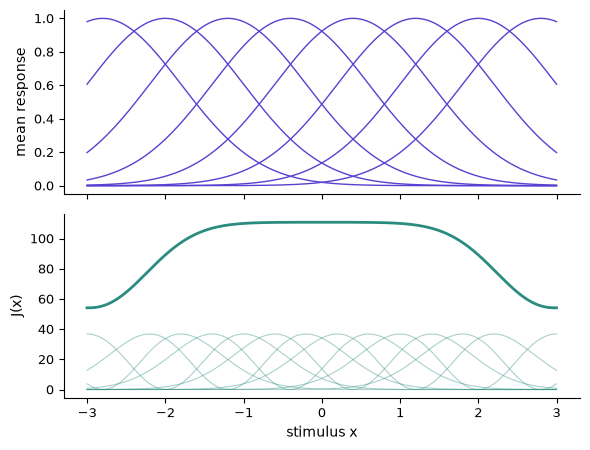

between -1.2 and 1.2: 108.9 to 110.8   (expected 108.9 to 110.8)
at x = 2: 89.1, at x = 3: 54.1   (expected 89.1 and 54.1)
CPU times: user 58.2 ms, sys: 2.54 ms, total: 60.8 ms
Wall time: 60.8 ms


In [11]:
%%time

CENTRES = torch.arange(-2.8, 2.81, 0.8, device=device)
curves = [bell(x - c) for c in CENTRES]
J_each = [compute_fisher(x, curve, SIGMA) for curve in curves]
J_population = sum(J_each)

fig, (ax, ax_j) = plt.subplots(2, 1, figsize=(6, 4.6), sharex=True)
for curve, J_i in zip(curves, J_each):
    ax.plot(x.cpu(), curve.cpu(), color=VIOLET, lw=1)
    ax_j.plot(x.cpu(), J_i.cpu(), color=TEAL, lw=0.8, alpha=0.4)
ax_j.plot(x.cpu(), J_population.cpu(), color=TEAL, lw=2)
ax.set_ylabel("mean response")
ax_j.set_ylabel("J(x)")
ax_j.set_xlabel("stimulus x")
plt.tight_layout()
plt.show()

middle = J_population[x.abs() <= 1.2 + 1e-9]
J_at_2 = J_population[torch.argmin((x - 2).abs())].item()
print(
    f"between -1.2 and 1.2: {middle.min().item():.1f} to {middle.max().item():.1f}"
    "   (expected 108.9 to 110.8)"
)
print(
    f"at x = 2: {J_at_2:.1f}, at x = 3: {J_population[-1].item():.1f}"
    "   (expected 89.1 and 54.1)"
)

Each stimulus now sits on the flank of some neuron, so the summed $J$ is nowhere near zero. In the middle of the range it is three times the best value of one neuron, and it falls towards the ends, where a stimulus has neurons on one side only.

## 7. Try it

* Double the noise to $\sigma = 0.2$. $J$ falls by a factor of four, and the ideal observer of the flank pair drops from 88% to 72% correct.
* Take the pair $x = -0.6$ and $x = 0.6$, a step of 1.2 across the peak. The exact $d'$ is zero, while $\sqrt{J(-0.6)}\,\delta$ predicts 6.0.
* Replace the Gaussian noise by Poisson noise, where the spike count has mean $A f(x)$ and variance $A f(x)$. The Fisher information becomes $J(x) = A f'(x)^2/f(x)$. Look at where it is largest.

The next cell carries out the last change, with a peak count $A = 20$. The maximum moves from $x = \pm 1$ to $x = \pm\sqrt{2} = \pm 1.41$, where the rate is lower and so is the noise.

time: <1 sec

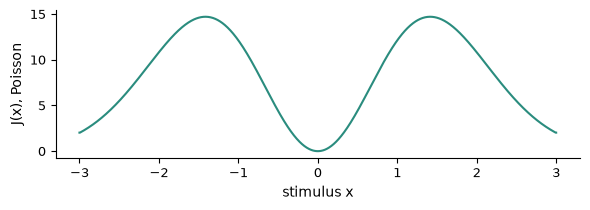

Poisson J is largest at |x| = 1.415   (expected sqrt(2) = 1.414)
CPU times: user 27.4 ms, sys: 1.27 ms, total: 28.7 ms
Wall time: 28.7 ms


In [12]:
%%time

PEAK_COUNT = 20.0
rate = PEAK_COUNT * f
(rate_slope,) = torch.gradient(rate, spacing=(x[1] - x[0]).item())
J_poisson = rate_slope**2 / rate

fig, ax = plt.subplots(figsize=(6, 2.2))
ax.plot(x.cpu(), J_poisson.cpu(), color=TEAL)
ax.set_xlabel("stimulus x")
ax.set_ylabel("J(x), Poisson")
plt.tight_layout()
plt.show()

x_max_poisson = x[torch.argmax(J_poisson)].abs().item()
print(f"Poisson J is largest at |x| = {x_max_poisson:.3f}   (expected sqrt(2) = 1.414)")

**Next**: [notebook f4](f4_from_fisher_to_geometry.ipynb) uses $J$ to measure distances between stimuli.